<a href="https://colab.research.google.com/github/Prem202920/Ensemble-Learning_SM1112/blob/main/Football_Player_Performance_Rating_Ensemble_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚽ Football Player Performance Rating Prediction Using Ensemble Learning

**Name:** Prem Patil  
**Roll No:** SM1112  
**Project Type:** Mini Project – Machine Learning

### Project Description
This project predicts football player performance ratings using player statistics from eight top European football leagues.

### New Approach
The original project used individual regression algorithms. This version extends the **same project, same title, same target and same datasets** using **Ensemble Learning**:

1. Linear Regression – baseline
2. Decision Tree – base learner
3. Bagging Regressor
4. Random Forest Regressor
5. Extra Trees Regressor
6. Voting Regressor
7. AdaBoost Regressor
8. Gradient Boosting Regressor
9. XGBoost Regressor
10. Stacking Regressor

The objective is to determine whether combining multiple learners produces better and more stable predictions than individual models.


In [ ]:
# Installing XGBoost if required in Google Colab
!pip -q install xgboost


In [ ]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    ExtraTreesRegressor,
    VotingRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
    StackingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

print("All libraries imported successfully!")


All libraries imported successfully!


## 1. Load the Dataset

The same two CSV files from the original project are used:
- `all_player_stats.csv`
- `all_player_profiles.csv`


In [ ]:
# Loading the same datasets used in the original project

stats_df = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/Mini-Project/all_player_stats.csv"
)

profiles_df = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/Mini-Project/all_player_profiles.csv"
)

print("Stats Dataset Shape:", stats_df.shape)
print("Profiles Dataset Shape:", profiles_df.shape)


Stats Dataset Shape: (3730, 17)
Profiles Dataset Shape: (4588, 5)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# View the first five records

print("Player Statistics:")
display(stats_df.head())

print("\nPlayer Profiles:")
display(profiles_df.head())


Player Statistics:


,player_id,league,appearances,matches_started,minutes_played,goals,assists,expected_goals,expected_assists,rating,total_shots,shots_on_target,yellow_cards,red_cards,tackles,interceptions,saves
0,804508,Premier League,31,24,2011,12,0,10.3733,1.773005,6.564516,47,18,5,0,6,1,0
1,934235,Premier League,27,22,2001,6,3,6.9941,5.761951,7.214815,63,26,1,0,36,14,0
2,794839,Premier League,12,2,320,2,0,1.8434,0.247789,6.541667,15,10,2,0,4,2,0
3,922573,Premier League,27,10,951,1,3,3.7215,1.012725,6.592593,26,11,2,0,11,1,0
4,836705,Premier League,8,5,408,1,1,2.5193,0.108973,6.637500,12,3,0,0,5,0,0



Player Profiles:


,player_id,name,league,position,market_value
0,804508,Viktor Gyökeres,Premier League,F,61000000.0
1,934235,Bukayo Saka,Premier League,F,126000000.0
2,794839,Gabriel Jesus,Premier League,F,21000000.0
3,922573,Gabriel Martinelli,Premier League,F,42000000.0
4,836705,Kai Havertz,Premier League,F,48000000.0


In [ ]:
# Display column names

print("Statistics Dataset Columns:")
print(stats_df.columns.tolist())

print("\nProfiles Dataset Columns:")
print(profiles_df.columns.tolist())


Statistics Dataset Columns:
['player_id', 'league', 'appearances', 'matches_started', 'minutes_played', 'goals', 'assists', 'expected_goals', 'expected_assists', 'rating', 'total_shots', 'shots_on_target', 'yellow_cards', 'red_cards', 'tackles', 'interceptions', 'saves']

Profiles Dataset Columns:
['player_id', 'name', 'league', 'position', 'market_value']


## 2. Merge the Datasets

The datasets are merged using `player_id` and `league`, exactly as in the original project.


In [ ]:
# Merging statistics and profile datasets

df = pd.merge(
    stats_df,
    profiles_df,
    on=["player_id", "league"],
    how="inner"
)

print("Merged Dataset Shape:", df.shape)
display(df.head())


Merged Dataset Shape: (3730, 20)


,player_id,league,appearances,matches_started,minutes_played,goals,assists,expected_goals,expected_assists,rating,total_shots,shots_on_target,yellow_cards,red_cards,tackles,interceptions,saves,name,position,market_value
0,804508,Premier League,31,24,2011,12,0,10.3733,1.773005,6.564516,47,18,5,0,6,1,0,Viktor Gyökeres,F,61000000.0
1,934235,Premier League,27,22,2001,6,3,6.9941,5.761951,7.214815,63,26,1,0,36,14,0,Bukayo Saka,F,126000000.0
2,794839,Premier League,12,2,320,2,0,1.8434,0.247789,6.541667,15,10,2,0,4,2,0,Gabriel Jesus,F,21000000.0
3,922573,Premier League,27,10,951,1,3,3.7215,1.012725,6.592593,26,11,2,0,11,1,0,Gabriel Martinelli,F,42000000.0
4,836705,Premier League,8,5,408,1,1,2.5193,0.108973,6.637500,12,3,0,0,5,0,0,Kai Havertz,F,48000000.0


In [ ]:
# Dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3730 entries, 0 to 3729
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   player_id         3730 non-null   int64  
 1   league            3730 non-null   object 
 2   appearances       3730 non-null   int64  
 3   matches_started   3730 non-null   int64  
 4   minutes_played    3730 non-null   int64  
 5   goals             3730 non-null   int64  
 6   assists           3730 non-null   int64  
 7   expected_goals    3182 non-null   float64
 8   expected_assists  3709 non-null   float64
 9   rating            3730 non-null   float64
 10  total_shots       3730 non-null   int64  
 11  shots_on_target   3730 non-null   int64  
 12  yellow_cards      3730 non-null   int64  
 13  red_cards         3730 non-null   int64  
 14  tackles           3730 non-null   int64  
 15  interceptions     3730 non-null   int64  
 16  saves             3730 non-null   int64  


In [ ]:
# Statistical summary

display(df.describe())


,player_id,appearances,matches_started,minutes_played,goals,assists,expected_goals,expected_assists,rating,total_shots,shots_on_target,yellow_cards,red_cards,tackles,interceptions,saves,market_value
count,3.730000e+03,3730.000000,3730.000000,3730.000000,3730.000000,3730.000000,3182.000000,3.709000e+03,3730.000000,3730.000000,3730.000000,3730.000000,3730.000000,3730.000000,3730.000000,3730.000000,3.670000e+03
mean,9.259223e+05,18.258981,13.172118,1184.995174,1.605630,1.131099,1.949644,1.172528e+00,6.720499,15.049866,5.183110,2.329491,0.119839,18.949062,9.959786,3.638070,9.918879e+06
std,4.611863e+05,9.120360,9.547604,810.190451,2.733682,1.727857,2.565948,1.443991e+00,0.625353,17.077511,6.981759,2.199616,0.351769,17.509545,10.530039,16.194426,1.653200e+07
min,7.910000e+02,1.000000,0.000000,1.000000,0.000000,0.000000,0.003200,9.300000e-07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.300000e+04
25%,8.009560e+05,10.000000,4.000000,478.000000,0.000000,0.000000,0.387275,1.593466e-01,6.600000,3.000000,0.000000,1.000000,0.000000,4.000000,1.000000,0.000000,1.100000e+06
50%,9.534320e+05,20.000000,12.000000,1103.500000,1.000000,0.000000,1.038700,6.790654e-01,6.742308,10.000000,3.000000,2.000000,0.000000,15.000000,6.000000,0.000000,3.700000e+06
75%,1.130258e+06,26.000000,21.000000,1857.000000,2.000000,2.000000,2.332825,1.615349e+00,6.905482,21.000000,7.000000,4.000000,0.000000,29.000000,16.000000,0.000000,1.160000e+07
max,2.492573e+06,33.000000,33.000000,2970.000000,32.000000,18.000000,24.909700,1.519518e+01,9.700000,122.000000,62.000000,12.000000,3.000000,104.000000,63.000000,145.000000,2.180000e+08


## 3. Data Cleaning

The original dataset contains missing values in `expected_goals`, `expected_assists` and `market_value`. Numerical missing values are filled with 0, duplicates are removed, and invalid target ratings equal to 0 are removed.


In [ ]:
# Checking missing values

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
player_id             0
league                0
appearances           0
matches_started       0
minutes_played        0
goals                 0
assists               0
expected_goals      548
expected_assists     21
rating                0
total_shots           0
shots_on_target       0
yellow_cards          0
red_cards             0
tackles               0
interceptions         0
saves                 0
name                  0
position              0
market_value         60
dtype: int64


In [ ]:
# Cleaning missing numerical values

numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns] = df[numeric_columns].fillna(0)

# Cleaning categorical values
df["position"] = df["position"].fillna("Unknown")

# Removing duplicate records
df = df.drop_duplicates()

print("Dataset after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())


Dataset after cleaning: (3730, 20)
Remaining missing values: 0


In [ ]:
# Removing invalid target values

df = df[df["rating"] > 0].copy()

print("Dataset after removing invalid ratings:", df.shape)
print("Minimum Rating:", df["rating"].min())
print("Maximum Rating:", df["rating"].max())


Dataset after removing invalid ratings: (3703, 20)
Minimum Rating: 5.3333333333333
Maximum Rating: 9.7


## 4. Basic Dataset Information

The cleaned dataset contains players from eight leagues and four main positions.


In [ ]:
print("Number of Players:", len(df))
print("Number of Leagues:", df["league"].nunique())
print("Number of Positions:", df["position"].nunique())

print("\nLeagues:")
print(df["league"].unique())

print("\nPositions:")
print(df["position"].unique())


Number of Players: 3703
Number of Leagues: 8
Number of Positions: 4

Leagues:
['Premier League' 'LaLiga' 'Serie A' 'Bundesliga' 'Ligue 1' 'Eredivisie'
 'Liga Portugal' 'Super Lig']

Positions:
['F' 'M' 'D' 'G']


## 5. Exploratory Data Analysis

These visualizations are retained from the original project so the ensemble-learning version remains comparable.


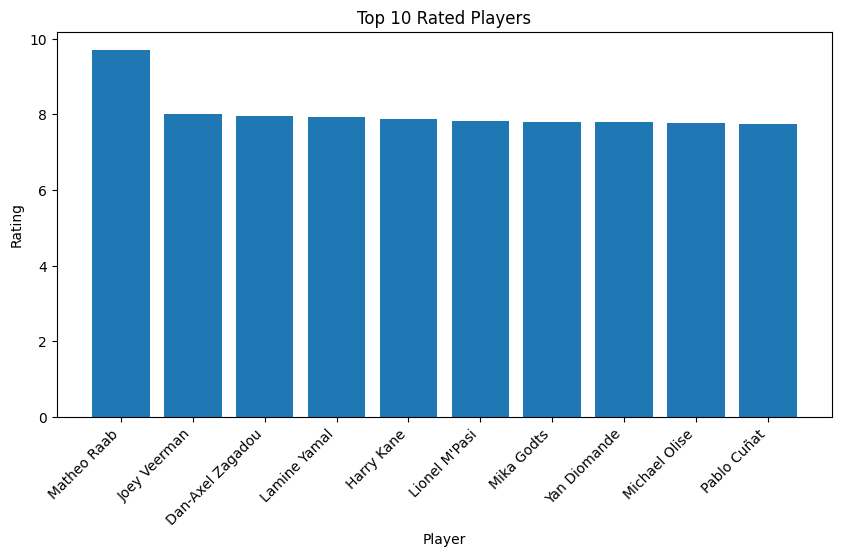

In [ ]:
# Top 10 rated players

top_players = df.sort_values("rating", ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_players["name"], top_players["rating"])
plt.xticks(rotation=45, ha="right")
plt.xlabel("Player")
plt.ylabel("Rating")
plt.title("Top 10 Rated Players")
plt.show()


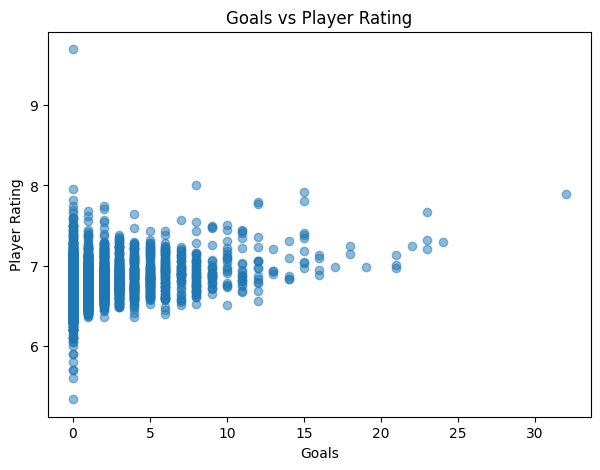

In [ ]:
# Rating vs Goals

plt.figure(figsize=(7, 5))
plt.scatter(df["goals"], df["rating"], alpha=0.5)
plt.xlabel("Goals")
plt.ylabel("Player Rating")
plt.title("Goals vs Player Rating")
plt.show()


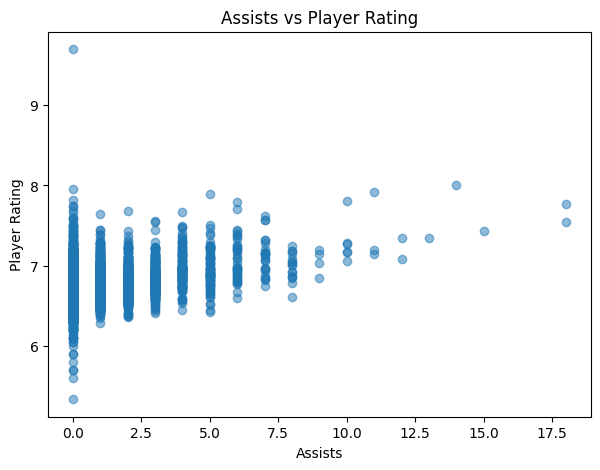

In [ ]:
# Rating vs Assists

plt.figure(figsize=(7, 5))
plt.scatter(df["assists"], df["rating"], alpha=0.5)
plt.xlabel("Assists")
plt.ylabel("Player Rating")
plt.title("Assists vs Player Rating")
plt.show()


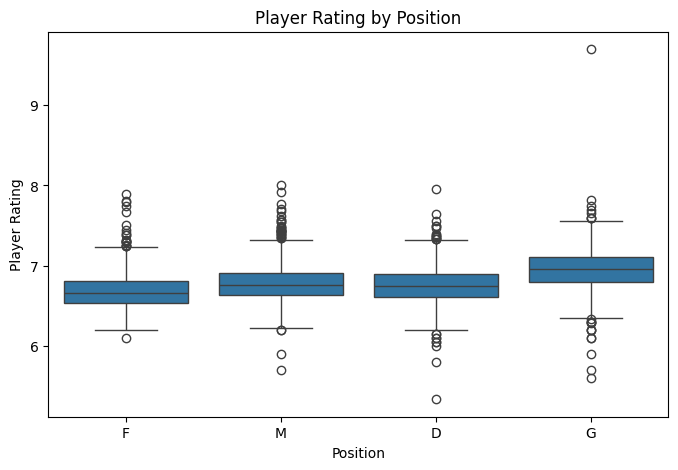

In [ ]:
# Rating by Position

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="position", y="rating")
plt.xlabel("Position")
plt.ylabel("Player Rating")
plt.title("Player Rating by Position")
plt.show()


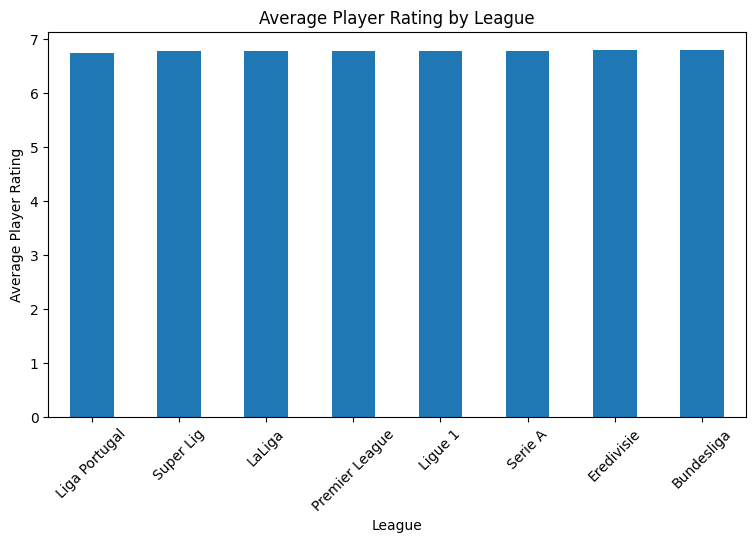

In [ ]:
# Average Rating by League

league_rating = (
    df.groupby("league")["rating"]
      .mean()
      .sort_values()
)

plt.figure(figsize=(9, 5))
league_rating.plot(kind="bar")
plt.xlabel("League")
plt.ylabel("Average Player Rating")
plt.title("Average Player Rating by League")
plt.xticks(rotation=45)
plt.show()


## 6. Feature Engineering

The same eight engineered features from the original project are retained:
- Goals per 90
- Assists per 90
- Total contribution
- Contribution per 90
- Goals per appearance
- Shot accuracy
- xG difference
- xA difference


In [ ]:
# Feature engineering

# Avoid division-by-zero problems
safe_minutes = df["minutes_played"].replace(0, np.nan)
safe_appearances = df["appearances"].replace(0, np.nan)

df["goals_per_90"] = (df["goals"] / safe_minutes) * 90
df["assists_per_90"] = (df["assists"] / safe_minutes) * 90

df["contribution"] = df["goals"] + df["assists"]

df["contribution_per_90"] = (
    df["goals_per_90"] + df["assists_per_90"]
)

df["goal_per_appearance"] = (
    df["goals"] / safe_appearances
)

df["shot_accuracy"] = (
    df["shots_on_target"] /
    (df["total_shots"] + 1)
)

df["xg_difference"] = (
    df["goals"] - df["expected_goals"]
)

df["xa_difference"] = (
    df["assists"] - df["expected_assists"]
)

# Replace any values created by zero denominators
df = df.replace([np.inf, -np.inf], np.nan)
df = df.fillna(0)

print("Feature engineering completed!")


Feature engineering completed!


In [ ]:
# Check engineered features

new_features = [
    "goals_per_90",
    "assists_per_90",
    "contribution",
    "contribution_per_90",
    "goal_per_appearance",
    "shot_accuracy",
    "xg_difference",
    "xa_difference"
]

display(df[new_features].head())


,goals_per_90,assists_per_90,contribution,contribution_per_90,goal_per_appearance,shot_accuracy,xg_difference,xa_difference
0,0.537046,0.000000,12,0.537046,0.387097,0.375000,1.6267,-1.773005
1,0.269865,0.134933,9,0.404798,0.222222,0.406250,-0.9941,-2.761951
2,0.562500,0.000000,2,0.562500,0.166667,0.625000,0.1566,-0.247789
3,0.094637,0.283912,4,0.378549,0.037037,0.407407,-2.7215,1.987275
4,0.220588,0.220588,2,0.441176,0.125000,0.230769,-1.5193,0.891027


## 7. Feature Selection

The target is `rating`. The same 22 numerical model features used in the original project are retained so that the comparison is fair.


In [ ]:
features = [
    "appearances",
    "matches_started",
    "minutes_played",
    "goals",
    "assists",
    "expected_goals",
    "expected_assists",
    "total_shots",
    "shots_on_target",
    "yellow_cards",
    "red_cards",
    "tackles",
    "interceptions",
    "saves",
    "goals_per_90",
    "assists_per_90",
    "contribution",
    "contribution_per_90",
    "goal_per_appearance",
    "shot_accuracy",
    "xg_difference",
    "xa_difference"
]

X = df[features]
y = df["rating"]

print("Number of Features:", X.shape[1])
print("Target Variable:", "rating")
display(X.head())


Number of Features: 22
Target Variable: rating


,appearances,matches_started,minutes_played,goals,assists,expected_goals,expected_assists,total_shots,shots_on_target,yellow_cards,...,interceptions,saves,goals_per_90,assists_per_90,contribution,contribution_per_90,goal_per_appearance,shot_accuracy,xg_difference,xa_difference
0,31,24,2011,12,0,10.3733,1.773005,47,18,5,...,1,0,0.537046,0.000000,12,0.537046,0.387097,0.375000,1.6267,-1.773005
1,27,22,2001,6,3,6.9941,5.761951,63,26,1,...,14,0,0.269865,0.134933,9,0.404798,0.222222,0.406250,-0.9941,-2.761951
2,12,2,320,2,0,1.8434,0.247789,15,10,2,...,2,0,0.562500,0.000000,2,0.562500,0.166667,0.625000,0.1566,-0.247789
3,27,10,951,1,3,3.7215,1.012725,26,11,2,...,1,0,0.094637,0.283912,4,0.378549,0.037037,0.407407,-2.7215,1.987275
4,8,5,408,1,1,2.5193,0.108973,12,3,0,...,0,0,0.220588,0.220588,2,0.441176,0.125000,0.230769,-1.5193,0.891027


## 8. Train-Test Split

An 80/20 split with `random_state=42` is used, matching the original project.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


Training Samples: 2962
Testing Samples: 741


# 9. Ensemble Learning

### Main ensemble techniques used

**Bagging:** trains multiple versions of a base learner on different samples and combines their predictions.

**Voting:** trains different models and averages their predictions.

**Boosting:** builds models sequentially, where later models focus on correcting earlier errors.

**Stacking:** uses predictions from multiple base models as input to a final meta-model.

We will compare all of these on the same test set.


## 10. Baseline Models

Linear Regression and a single Decision Tree are included as reference models.


In [ ]:
# Linear Regression baseline

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("-----------------")
print("MAE :", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R²  :", round(linear_r2, 4))


Linear Regression
-----------------
MAE : 0.1291
RMSE: 0.1828
R²  : 0.4621


In [ ]:
# Single Decision Tree baseline

tree_model = DecisionTreeRegressor(
    max_depth=8,
    random_state=42
)

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Regressor")
print("-----------------------")
print("MAE :", round(tree_mae, 4))
print("RMSE:", round(tree_rmse, 4))
print("R²  :", round(tree_r2, 4))


Decision Tree Regressor
-----------------------
MAE : 0.141
RMSE: 0.196
R²  : 0.3819


## 11. Bagging

Bagging creates multiple models using bootstrap samples of the training data and averages their predictions.

Here, a Decision Tree is used as the base estimator.


In [ ]:
# Bagging Regressor

bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=8, random_state=42),
    n_estimators=200,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)
bagging_pred = bagging_model.predict(X_test)

bagging_mae = mean_absolute_error(y_test, bagging_pred)
bagging_rmse = np.sqrt(mean_squared_error(y_test, bagging_pred))
bagging_r2 = r2_score(y_test, bagging_pred)

print("Bagging Regressor")
print("-----------------")
print("MAE :", round(bagging_mae, 4))
print("RMSE:", round(bagging_rmse, 4))
print("R²  :", round(bagging_r2, 4))


Bagging Regressor
-----------------
MAE : 0.1268
RMSE: 0.1779
R²  : 0.4906


## 12. Random Forest – Bagging-Based Ensemble

Random Forest is an advanced bagging method. It uses bootstrap samples and random feature subsets while growing many decision trees.


In [ ]:
# Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Regressor")
print("-----------------------")
print("MAE :", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R²  :", round(rf_r2, 4))


Random Forest Regressor
-----------------------
MAE : 0.1264
RMSE: 0.1777
R²  : 0.4917


## 13. Extra Trees

Extra Trees is another tree ensemble. It introduces additional randomness in the selection of split points and combines many trees.


In [ ]:
# Extra Trees Regressor

extra_model = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

extra_model.fit(X_train, y_train)
extra_pred = extra_model.predict(X_test)

extra_mae = mean_absolute_error(y_test, extra_pred)
extra_rmse = np.sqrt(mean_squared_error(y_test, extra_pred))
extra_r2 = r2_score(y_test, extra_pred)

print("Extra Trees Regressor")
print("--------------------")
print("MAE :", round(extra_mae, 4))
print("RMSE:", round(extra_rmse, 4))
print("R²  :", round(extra_r2, 4))


Extra Trees Regressor
--------------------
MAE : 0.1284
RMSE: 0.1785
R²  : 0.4872


## 14. Voting Regressor

Voting combines predictions from different regression models. Here, Linear Regression, Random Forest and Gradient Boosting are combined.


In [ ]:
# Base models for Voting

voting_linear = LinearRegression()

voting_rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

voting_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

voting_model = VotingRegressor(
    estimators=[
        ("linear", voting_linear),
        ("random_forest", voting_rf),
        ("gradient_boosting", voting_gb)
    ],
    weights=[1, 2, 2]
)

voting_model.fit(X_train, y_train)
voting_pred = voting_model.predict(X_test)

voting_mae = mean_absolute_error(y_test, voting_pred)
voting_rmse = np.sqrt(mean_squared_error(y_test, voting_pred))
voting_r2 = r2_score(y_test, voting_pred)

print("Voting Regressor")
print("----------------")
print("MAE :", round(voting_mae, 4))
print("RMSE:", round(voting_rmse, 4))
print("R²  :", round(voting_r2, 4))


Voting Regressor
----------------
MAE : 0.1238
RMSE: 0.174
R²  : 0.5128


# 15. Boosting

Boosting builds models sequentially. Each new weak learner attempts to improve the errors made by the previous learners.

We demonstrate three boosting approaches:
- AdaBoost
- Gradient Boosting
- XGBoost


## 15.1 AdaBoost Regressor

AdaBoost gives greater emphasis to observations that were predicted poorly by previous weak learners.


In [ ]:
# AdaBoost Regressor

adaboost_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3, random_state=42),
    n_estimators=200,
    learning_rate=0.05,
    random_state=42
)

adaboost_model.fit(X_train, y_train)
adaboost_pred = adaboost_model.predict(X_test)

adaboost_mae = mean_absolute_error(y_test, adaboost_pred)
adaboost_rmse = np.sqrt(mean_squared_error(y_test, adaboost_pred))
adaboost_r2 = r2_score(y_test, adaboost_pred)

print("AdaBoost Regressor")
print("------------------")
print("MAE :", round(adaboost_mae, 4))
print("RMSE:", round(adaboost_rmse, 4))
print("R²  :", round(adaboost_r2, 4))


AdaBoost Regressor
------------------
MAE : 0.1546
RMSE: 0.2087
R²  : 0.2988


## 15.2 Gradient Boosting Regressor

Gradient Boosting builds trees sequentially to reduce the residual errors of previous trees.


In [ ]:
# Gradient Boosting Regressor

gradient_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    random_state=42
)

gradient_model.fit(X_train, y_train)
gradient_pred = gradient_model.predict(X_test)

gradient_mae = mean_absolute_error(y_test, gradient_pred)
gradient_rmse = np.sqrt(mean_squared_error(y_test, gradient_pred))
gradient_r2 = r2_score(y_test, gradient_pred)

print("Gradient Boosting Regressor")
print("---------------------------")
print("MAE :", round(gradient_mae, 4))
print("RMSE:", round(gradient_rmse, 4))
print("R²  :", round(gradient_r2, 4))


Gradient Boosting Regressor
---------------------------
MAE : 0.1239
RMSE: 0.1737
R²  : 0.5146


## 15.3 XGBoost

XGBoost is a regularized gradient-boosting implementation designed for efficient and accurate learning on tabular data.


In [ ]:
# XGBoost Regressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost Regressor")
print("-----------------")
print("MAE :", round(xgb_mae, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R²  :", round(xgb_r2, 4))


XGBoost Regressor
-----------------
MAE : 0.1248
RMSE: 0.1767
R²  : 0.4974


# 16. Stacking

Stacking combines several different base models. Their predictions are passed to a final **meta-model**, which learns how to combine those predictions.

Here:
- Base model 1: Linear Regression
- Base model 2: Random Forest
- Base model 3: Gradient Boosting
- Meta-model: Ridge/Linear Regression

The stacking model uses cross-validation internally to reduce information leakage from the base learners.


In [ ]:
# Stacking Regressor

stacking_model = StackingRegressor(
    estimators=[
        ("linear", LinearRegression()),
        ("random_forest", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )),
        ("gradient_boosting", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ],
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)
stacking_pred = stacking_model.predict(X_test)

stacking_mae = mean_absolute_error(y_test, stacking_pred)
stacking_rmse = np.sqrt(mean_squared_error(y_test, stacking_pred))
stacking_r2 = r2_score(y_test, stacking_pred)

print("Stacking Regressor")
print("------------------")
print("MAE :", round(stacking_mae, 4))
print("RMSE:", round(stacking_rmse, 4))
print("R²  :", round(stacking_r2, 4))


Stacking Regressor
------------------
MAE : 0.1236
RMSE: 0.1738
R²  : 0.5139


# 17. Complete Model Comparison

All models are evaluated using:
- **MAE** – lower is better
- **RMSE** – lower is better
- **R²** – higher is better


In [ ]:
# Creating the final comparison table

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Bagging Regressor",
        "Random Forest",
        "Extra Trees",
        "Voting Regressor",
        "AdaBoost",
        "Gradient Boosting",
        "XGBoost",
        "Stacking Regressor"
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        bagging_mae,
        rf_mae,
        extra_mae,
        voting_mae,
        adaboost_mae,
        gradient_mae,
        xgb_mae,
        stacking_mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        bagging_rmse,
        rf_rmse,
        extra_rmse,
        voting_rmse,
        adaboost_rmse,
        gradient_rmse,
        xgb_rmse,
        stacking_rmse
    ],
    "R2 Score": [
        linear_r2,
        tree_r2,
        bagging_r2,
        rf_r2,
        extra_r2,
        voting_r2,
        adaboost_r2,
        gradient_r2,
        xgb_r2,
        stacking_r2
    ]
})

results = results.sort_values("R2 Score", ascending=False).reset_index(drop=True)

display(results.round(4))


,Model,MAE,RMSE,R2 Score
0,Gradient Boosting,0.1239,0.1737,0.5146
1,Stacking Regressor,0.1236,0.1738,0.5139
2,Voting Regressor,0.1238,0.1740,0.5128
3,XGBoost,0.1248,0.1767,0.4974
4,Random Forest,0.1264,0.1777,0.4917
5,Bagging Regressor,0.1268,0.1779,0.4906
6,Extra Trees,0.1284,0.1785,0.4872
7,Linear Regression,0.1291,0.1828,0.4621
8,Decision Tree,0.1410,0.1960,0.3819
9,AdaBoost,0.1546,0.2087,0.2988


In [ ]:
# Best model based on R²

best_model_name = results.loc[0, "Model"]
best_r2 = results.loc[0, "R2 Score"]

print("Best Ensemble/Regression Model:", best_model_name)
print("Best R² Score:", round(best_r2, 4))


## 18. R² Comparison


In [ ]:
# Plot R² scores

plt.figure(figsize=(12, 6))

plt.bar(results["Model"], results["R2 Score"])

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Comparison of Regression and Ensemble Models")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 19. MAE Comparison


In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(results["Model"], results["MAE"])

plt.xlabel("Model")
plt.ylabel("MAE")
plt.title("MAE Comparison – Lower is Better")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 20. RMSE Comparison


In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(results["Model"], results["RMSE"])

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("RMSE Comparison – Lower is Better")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 21. Feature Importance

Feature importance from XGBoost is used to understand which statistics contribute most to the prediction.


In [ ]:
# XGBoost feature importance

importance = pd.Series(
    xgb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 8))
importance.plot(kind="barh")

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()


# 22. Actual vs Predicted Rating – Best Model

The best model selected by R² is used for the final prediction analysis.


In [ ]:
# Select prediction array for the best model

prediction_map = {
    "Linear Regression": linear_pred,
    "Decision Tree": tree_pred,
    "Bagging Regressor": bagging_pred,
    "Random Forest": rf_pred,
    "Extra Trees": extra_pred,
    "Voting Regressor": voting_pred,
    "AdaBoost": adaboost_pred,
    "Gradient Boosting": gradient_pred,
    "XGBoost": xgb_pred,
    "Stacking Regressor": stacking_pred
}

best_pred = prediction_map[best_model_name]

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    best_pred,
    alpha=0.6
)

min_value = min(y_test.min(), best_pred.min())
max_value = max(y_test.max(), best_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title(f"Actual vs Predicted Rating – {best_model_name}")

plt.show()


# 23. Prediction Error Distribution


In [ ]:
errors = y_test - best_pred

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=30)

plt.xlabel("Prediction Error")
plt.ylabel("Number of Players")
plt.title(f"Prediction Error Distribution – {best_model_name}")

plt.show()


# 24. Prediction Table


In [ ]:
# Creating prediction results

prediction_results = df.loc[
    X_test.index,
    ["name", "position", "league"]
].copy()

prediction_results["Actual Rating"] = y_test
prediction_results["Predicted Rating"] = best_pred

prediction_results["Absolute Error"] = abs(
    prediction_results["Actual Rating"] -
    prediction_results["Predicted Rating"]
)

prediction_results = prediction_results.sort_values(
    "Absolute Error"
)

display(prediction_results.head(20))


# 25. Predict a Player's Rating

This function allows a player's rating to be predicted using the selected best model.


In [ ]:
def predict_player_rating(player_name):

    player = df[
        df["name"].str.lower() == player_name.lower()
    ]

    if player.empty:
        print("Player not found.")
        return

    player_features = player[features]

    prediction = prediction_map[best_model_name]

    # Use the actual trained model for a new prediction
    model_objects = {
        "Linear Regression": linear_model,
        "Decision Tree": tree_model,
        "Bagging Regressor": bagging_model,
        "Random Forest": rf_model,
        "Extra Trees": extra_model,
        "Voting Regressor": voting_model,
        "AdaBoost": adaboost_model,
        "Gradient Boosting": gradient_model,
        "XGBoost": xgb_model,
        "Stacking Regressor": stacking_model
    }

    selected_model = model_objects[best_model_name]
    predicted_rating = selected_model.predict(player_features)[0]

    print("Player:", player.iloc[0]["name"])
    print("Position:", player.iloc[0]["position"])
    print("League:", player.iloc[0]["league"])
    print("Actual Rating:", round(player.iloc[0]["rating"], 2))
    print("Predicted Rating:", round(predicted_rating, 2))
    print("Model Used:", best_model_name)


In [ ]:
# Example prediction

predict_player_rating("Bruno Fernandes")


# 26. Final Conclusion

This ensemble-learning version keeps the original football player rating prediction problem but expands the modelling stage from individual algorithms to multiple ensemble strategies.

### Techniques demonstrated
- **Bagging:** Bagging Regressor and Random Forest
- **Voting:** Voting Regressor
- **Boosting:** AdaBoost, Gradient Boosting and XGBoost
- **Stacking:** Stacking Regressor
- **Additional ensemble:** Extra Trees

The final model is selected automatically using the highest **R² score**, while MAE and RMSE are also reported.

### Important interpretation
A higher R² and lower MAE/RMSE indicate better prediction performance. The ensemble approach should be compared against the original XGBoost result rather than assuming that an ensemble will always perform better.

The original project achieved approximately **0.4974 R² with XGBoost** on the same 741-player test set. The new notebook will calculate the ensemble results on that same setup, allowing a direct and fair comparison.
